# Scenarios 1 and 2 (seed 4126): training curves and client selection

Random vs Wen et al. vs Ours (GPU estimator).

* **Wen et al.** = `S1_wen_s4126`, the original Wen-faithful selector (F3 = each vehicle's last reported loss).
* **Wen et al. (fresh F3)** = `S1_wen_fresh_s4126`, identical except F3 is re-evaluated with the current global model at every merge. Drop it from `METHODS` for a 3-method figure. Kernel: **Python (plato .venv)**.

* Fig. 1 - accuracy vs simulated time and vs round
* Fig. 2 - tier share of dispatches per method (+ the fleet)
* Fig. 3 - tier share per accuracy phase (0-80 / 80-85 / 85-90 %)
* Fig. 4 - why Ours is faster per round: where the time goes, distance to the RSU at upload, per-vehicle concentration
* Table - the numbers behind the figures

Every statistic is computed from the dispatch log up to the run's TTA@90 % round
(neither Wen run reaches 90 %, so their whole 4,000-round runs are used).
Set `SAVE = True` to write PNG + PDF to `FIG_DIR`.

**Scenario 2** (bottom of the notebook) repeats Fig. 1-4 and the table for
Random + Stage 0 vs Wen et al. (fresh F3) + Stage 0 vs Ours + Stage 0.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate examples/async/fedasync no matter where the notebook is opened from.
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs" / "wen_env").is_dir())
RUNS_DIR = BASE / "runs" / "wen_env"

# label -> (run directory, last round used, colour)
# Ours: the run hung at r1957 when the disk filled; 89.75 % is counted as 90 % (user decision,
# wen_faithful_v1_step6_footnote.md), first reached at round 1950.
METHODS = {
    "Random": ("S1_random_s4126", None, "#1baf7a"),
    "Wen et al.": ("S1_wen_s4126", None, "#eb6834"),                 # original (Wen-faithful) selector
    "Wen et al. (fresh F3)": ("S1_wen_fresh_s4126", None, "#eda100"),  # same, F3 re-evaluated every merge
    "Ours": ("_failed/S1_gpu_s4126_hung_diskfull_0740", 1950, "#2a78d6"),
}
TARGET_OVERRIDE = {"Ours": 0.8975}       # accuracy that counts as 90 % for that run
LEVELS = (0.80, 0.85, 0.90)
TIERS = ["xavier", "orin", "thor"]       # slowest -> fastest GPU
TIER_LABEL = {"xavier": "Xavier", "orin": "Orin", "thor": "Thor"}
TIER_COLOR = {"xavier": "#c9c2f2", "orin": "#8a7ce6", "thor": "#4231a8"}  # one hue, light -> dark
FLEET = {"xavier": 15, "orin": 10, "thor": 5}                           # n30_x15-o10-t5

SAVE = False
FIG_DIR = BASE / "wen_env" / "evidence" / "figs_s1"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2a",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

def save(fig, name, fig_dir=FIG_DIR):
    if SAVE:
        fig_dir.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "pdf"):
            fig.savefig(fig_dir / f"{name}.{ext}", bbox_inches="tight")

In [4]:
def load(label, methods=METHODS, target_override=TARGET_OVERRIDE):
    run, cut, _ = methods[label]
    d = RUNS_DIR / run
    res = pd.read_csv(next((d / "results").glob("*.csv")))
    dl = pd.read_csv(d / "dispatch_log.csv")
    # TTA at each level = first evaluated round at or above it
    tta = {}
    for lv in LEVELS:
        thr = target_override.get(label, lv) if lv == 0.90 else lv
        hit = res[res["accuracy"] >= thr - 1e-12]
        tta[lv] = (float(hit["elapsed_time"].iloc[0]), int(hit["round"].iloc[0])) if len(hit) else None
    last = cut or (tta[0.90][1] if tta[0.90] else int(res["round"].max()))
    res = res[res["round"] <= last]
    dl = dl[dl["round"] <= last].copy()
    # accuracy phase each dispatch belongs to
    edges = [0] + [tta[lv][1] if tta[lv] else last for lv in LEVELS]
    edges = sorted(set(edges))
    names = ["0-80%", "80-85%", "85-90%"][: len(edges) - 1]
    dl["phase"] = pd.cut(dl["round"], edges, labels=names, include_lowest=True)
    return {"res": res, "dl": dl, "tta": tta, "last": last}

def report(data):
    for m, v in data.items():
        print(f"{m:10s} rounds used {v['last']:5d}  dispatches {len(v['dl']):5d}  TTA:",
              {f"{lv:.0%}": (f"{t[0]:.0f}s r{t[1]}" if t else "not reached") for lv, t in v["tta"].items()})

data = {m: load(m) for m in METHODS}
report(data)

Random     rounds used  1770  dispatches  1772  TTA: {'80%': '1419s r380', '85%': '2568s r680', '90%': '6645s r1770'}
Wen et al. rounds used  4000  dispatches  4002  TTA: {'80%': '2625s r760', '85%': '11049s r3200', '90%': 'not reached'}
Wen et al. (fresh F3) rounds used  4000  dispatches  4002  TTA: {'80%': '1967s r560', '85%': '7263s r2100', '90%': 'not reached'}
Ours       rounds used  1950  dispatches  1952  TTA: {'80%': '1158s r390', '85%': '2089s r680', '90%': '6326s r1950'}


## Fig. 1 - Training curves

The server evaluates every 10 rounds, so only evaluation rounds are plotted. Dots mark the
first time each method reaches 80 / 85 / 90 %.

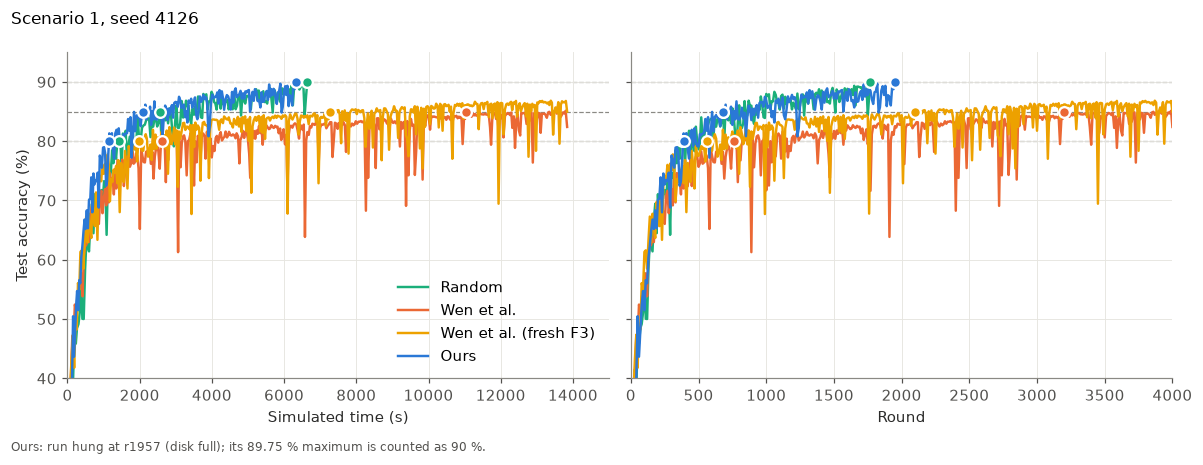

In [5]:
def plot_curves(data, methods, title, name, fig_dir=FIG_DIR, xmax=(15000, 4000), note=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, xkey, xlabel in [(axes[0], "elapsed_time", "Simulated time (s)"), (axes[1], "round", "Round")]:
        for m, v in data.items():
            col = methods[m][2]
            r = v["res"]
            r = r[(r["round"] % 10 == 0) | (r["round"] == r["round"].max())]
            ax.plot(r[xkey], r["accuracy"] * 100, color=col, lw=1.6, label=m)
            for lv, t in v["tta"].items():
                if t:
                    ax.plot(t[0] if xkey == "elapsed_time" else t[1], lv * 100, "o", ms=7,
                            color=col, mec="white", mew=1.5, zorder=5)
        for lv in LEVELS:
            ax.axhline(lv * 100, color="#8a8984", lw=0.8, ls="--", zorder=0)
        ax.set_xlabel(xlabel)
        ax.set_ylim(40, 95)
    axes[0].set_ylabel("Test accuracy (%)")
    axes[0].legend(loc="lower right")
    axes[0].set_xlim(0, xmax[0])
    axes[1].set_xlim(0, xmax[1])
    fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    if note:
        fig.text(0.01, -0.02, note, fontsize=8, color="#52514e")
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()

plot_curves(data, METHODS, "Scenario 1, seed 4126", "s1_training_curves",
            note="Ours: run hung at r1957 (disk full); its 89.75 % maximum is counted as 90 %.")

## Fig. 2 - Which vehicle types each method dispatches

Share of dispatches per GPU tier, up to TTA@90 % (Wen: whole run). The top bar is the fleet
itself (15 Xavier / 10 Orin / 5 Thor): a method that picks uniformly at random matches it.

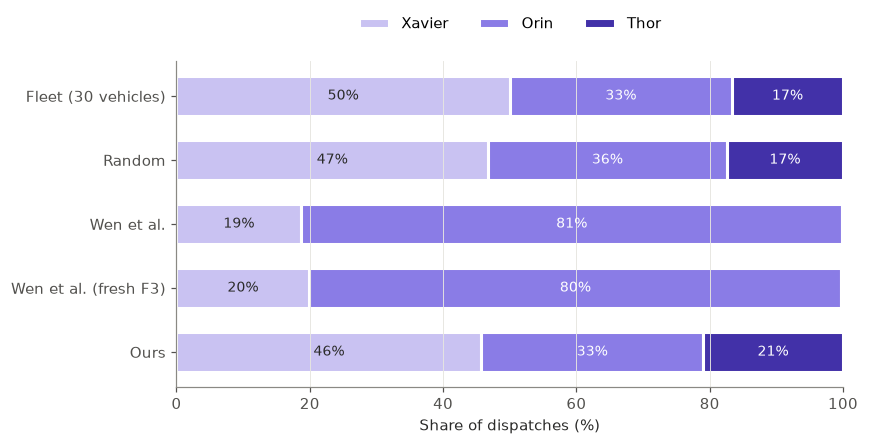

,xavier,orin,thor
Fleet (30 vehicles),50.0,33.3,16.7
Random,46.7,35.8,17.4
Wen et al.,18.7,81.2,0.1
Wen et al. (fresh F3),19.9,79.8,0.2
Ours,45.7,33.2,21.0


In [6]:
def tier_share(df):
    return df["tier"].value_counts(normalize=True).reindex(TIERS, fill_value=0) * 100


def plot_tier_share(data, name, fig_dir=FIG_DIR):
    rows = {"Fleet (30 vehicles)": pd.Series(FLEET).reindex(TIERS) / sum(FLEET.values()) * 100}
    rows.update({m: tier_share(v["dl"]) for m, v in data.items()})
    share = pd.DataFrame(rows).T

    fig, ax = plt.subplots(figsize=(8, 0.75 * len(data) + 1.2))
    y = np.arange(len(share))[::-1]
    left = np.zeros(len(share))
    for t in TIERS:
        ax.barh(y, share[t], left=left, color=TIER_COLOR[t], edgecolor="white", linewidth=2,
                height=0.62, label=TIER_LABEL[t])
        for yi, l, w in zip(y, left, share[t]):
            if w >= 4:
                ax.text(l + w / 2, yi, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                        color="white" if t != "xavier" else "#2b2b2a")
        left += share[t].values
    ax.set_yticks(y, share.index)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Share of dispatches (%)")
    ax.grid(axis="y", visible=False)
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()
    return share.round(1)


plot_tier_share(data, "s1_tier_share")

## Fig. 3 - Tier share per accuracy phase

Phase boundaries are each method's own TTA@80 % and TTA@85 % rounds.

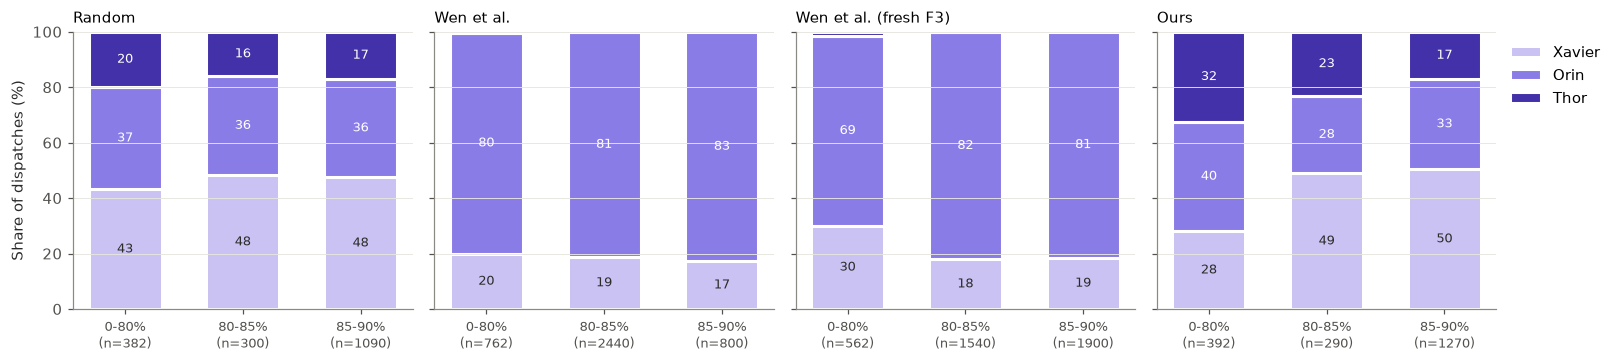

In [13]:
def plot_tier_share_by_phase(data, name, fig_dir=FIG_DIR):
    fig, axes = plt.subplots(1, len(data), figsize=(3.7 * len(data), 3.4), sharey=True)
    for ax, (m, v) in zip(axes, data.items()):
        ph = (v["dl"].groupby("phase", observed=True)["tier"].value_counts(normalize=True)
              .unstack().reindex(columns=TIERS, fill_value=0) * 100)
        x = np.arange(len(ph))
        bottom = np.zeros(len(ph))
        for t in TIERS:
            ax.bar(x, ph[t], bottom=bottom, color=TIER_COLOR[t], edgecolor="white", linewidth=2,
                   width=0.62, label=TIER_LABEL[t])
            for xi, b, h in zip(x, bottom, ph[t]):
                if h >= 6:
                    ax.text(xi, b + h / 2, f"{h:.0f}", ha="center", va="center", fontsize=8.5,
                            color="white" if t != "xavier" else "#2b2b2a")
            bottom += ph[t].values
        n = v["dl"].groupby("phase", observed=True).size()
        ax.set_xticks(x, [f"{p}\n(n={n[p]})" for p in ph.index], fontsize=8.5)
        ax.set_title(m, fontsize=10, loc="left")
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("Share of dispatches (%)")
    axes[0].set_ylim(0, 100)
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()

plot_tier_share_by_phase(data, "s1_tier_share_by_phase")

## Fig. 4 - Why Ours is faster per round

With C = 3 vehicles in flight, seconds per round ≈ mean dispatch duration / 3, and a dispatch's
duration is training time plus upload time. (a) splits the mean duration into these two parts.
(b) shows the vehicle's distance to the RSU when it starts uploading, which sets the upload rate.
(c) shows how evenly each method spreads its dispatches over the 30 vehicles, which affects how many
rounds the model needs.

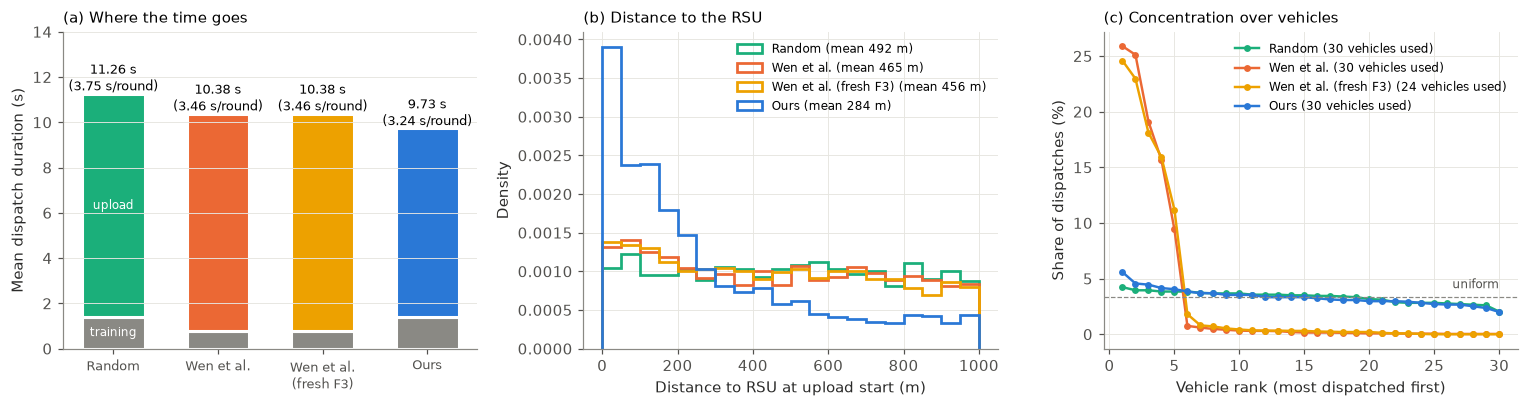

In [14]:
def plot_why(data, methods, name, fig_dir=FIG_DIR):
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

    # (a) mean duration = training + upload
    ax = axes[0]
    names = list(data)
    tr = [data[m]["dl"]["T_train_true"].mean() for m in names]
    up = [data[m]["dl"]["T_up_true"].mean() for m in names]
    x = np.arange(len(names))
    ax.bar(x, tr, color="#8a8984", width=0.6, edgecolor="white", linewidth=2, label="Training")
    ax.bar(x, up, bottom=tr, color=[methods[m][2] for m in names], width=0.6, edgecolor="white",
           linewidth=2, label="Upload")
    for xi, a, b in zip(x, tr, up):
        ax.text(xi, a + b + 0.15, f"{a + b:.2f} s\n({(a + b) / 3:.2f} s/round)", ha="center", fontsize=8.5)
    ax.set_xticks(x, [n.replace(" (", "\n(") for n in names], fontsize=8.5)
    ax.set_ylabel("Mean dispatch duration (s)")
    ax.set_ylim(0, max(a + b for a, b in zip(tr, up)) * 1.35)
    ax.set_title("(a) Where the time goes", loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.text(x[0], tr[0] / 2, "training", ha="center", va="center", fontsize=8, color="white")
    ax.text(x[0], tr[0] + up[0] / 2, "upload", ha="center", va="center", fontsize=8, color="white")

    # (b) distance to RSU at training finish (= start of upload)
    ax = axes[1]
    bins = np.linspace(0, 1000, 21)
    for m in names:
        d = data[m]["dl"]["d_finish"]
        ax.hist(d, bins=bins, histtype="step", lw=1.8, color=methods[m][2], density=True,
                label=f"{m} (mean {d.mean():.0f} m)")
    ax.set_xlabel("Distance to RSU at upload start (m)")
    ax.set_ylabel("Density")
    ax.set_title("(b) Distance to the RSU", loc="left", fontsize=10)
    ax.legend(fontsize=8)

    # (c) per-vehicle share of dispatches, sorted
    ax = axes[2]
    for m in names:
        c = data[m]["dl"]["veh_id"].value_counts().reindex([f"veh{i:02d}" for i in range(30)], fill_value=0)
        s = np.sort(c.values)[::-1] / c.sum() * 100
        ax.plot(np.arange(1, 31), s, "-o", ms=3.5, lw=1.6, color=methods[m][2],
                label=f"{m} ({(c > 0).sum()} vehicles used)")
    ax.axhline(100 / 30, color="#8a8984", lw=0.8, ls="--")
    ax.text(30, 100 / 30 + 0.8, "uniform", ha="right", fontsize=8, color="#52514e")
    ax.set_xlabel("Vehicle rank (most dispatched first)")
    ax.set_ylabel("Share of dispatches (%)")
    ax.set_title("(c) Concentration over vehicles", loc="left", fontsize=10)
    ax.legend(fontsize=8)

    fig.tight_layout()
    save(fig, name, fig_dir)
    plt.show()

plot_why(data, METHODS, "s1_why_ours_faster")

## Table - numbers behind the figures

In [15]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())


def summary_table(data):
    summary = {}
    for m, v in data.items():
        dl = v["dl"]
        t90 = v["tta"][0.90]
        c = dl["veh_id"].value_counts().reindex([f"veh{i:02d}" for i in range(30)], fill_value=0)
        summary[m] = {
            "TTA@90% (s)": f"{t90[0]:.0f}" if t90 else "not reached",
            "rounds used": v["last"],
            "s / round": round(dl["t_finish_clean"].max() / v["last"], 2) if v["last"] else None,
            "mean duration (s)": round(dl["duration"].mean(), 2),
            "  training (s)": round(dl["T_train_true"].mean(), 2),
            "  upload (s)": round(dl["T_up_true"].mean(), 2),
            "distance to RSU at upload (m)": round(dl["d_finish"].mean(), 0),
            "Xavier / Orin / Thor (%)": " / ".join(f"{s:.0f}" for s in tier_share(dl)),
            "vehicles used": int((c > 0).sum()),
            "Gini of per-vehicle dispatches": round(gini(c), 3),
            "top-5 vehicles' share (%)": round(c.nlargest(5).sum() / c.sum() * 100, 1),
        }
    return pd.DataFrame(summary)


summary_table(data)

,Random,Wen et al.,Wen et al. (fresh F3),Ours
TTA@90% (s),6645,not reached,not reached,6326
rounds used,1770,4000,4000,1950
s / round,3.76,3.46,3.46,3.25
mean duration (s),11.26,10.38,10.38,9.73
training (s),1.38,0.76,0.8,1.38
upload (s),9.88,9.61,9.58,8.35
distance to RSU at upload (m),492.0,465.0,456.0,284.0
Xavier / Orin / Thor (%),47 / 36 / 17,19 / 81 / 0,20 / 80 / 0,46 / 33 / 21
vehicles used,30,30,24,30
Gini of per-vehicle dispatches,0.084,0.834,0.819,0.115


## Summary - one row per method

TTA at each level (simulated seconds and round), tier share of dispatches, seconds per round,
distance to the RSU at upload start, and how concentrated the dispatches are over the 30 vehicles.

In [ ]:
def compact_table(data):
    rows = {}
    for m, v in data.items():
        dl = v["dl"]
        c = dl["veh_id"].value_counts().reindex([f"veh{i:02d}" for i in range(30)], fill_value=0)
        row = {f"TTA@{lv:.0%}": f"{t[0]:,.0f} s (r{t[1]})" if t else "not reached"
               for lv, t in v["tta"].items()}
        row["Xavier / Orin / Thor (%)"] = " / ".join(f"{s:.1f}" for s in tier_share(dl))
        row["s / round"] = round(dl["t_finish_clean"].max() / v["last"], 2)
        row["distance to RSU at upload (m)"] = round(dl["d_finish"].mean())
        row["Gini / top-5 share"] = f"{gini(c):.3f} / {c.nlargest(5).sum() / c.sum() * 100:.1f} %"
        rows[m] = row
    return pd.DataFrame(rows).T


compact_table(data)

# Scenario 2 (seed 4126)

Random + Stage 0 vs Wen et al. (fresh F3) + Stage 0 vs Ours + Stage 0, same fleet (n30_x15-o10-t5).

* **Random + Stage 0** = `S2_random_s0_s4126` (egreedy, eps = 1.0, Stage 0 on).
* **Wen et al. (fresh F3) + Stage 0** = `S2_wen_fresh_s0_s4126` (same selector as S1's fresh-F3 run, Stage 0 on).
* **Ours + Stage 0** = `S2_gpu_stage0_s4126` (GPU estimator, egreedy eps = 0.2, Stage 0 on).
  Swap in `S2_gpu_s4126` for Ours without Stage 0.

All three runs reach 90 %, so every statistic is computed up to each run's own TTA@90 % round (no override).
Figures go to `FIG_DIR_S2`.

In [ ]:
METHODS_S2 = {
    "Random + Stage 0": ("S2_random_s0_s4126", None, "#1baf7a"),
    "Wen et al. (fresh F3) + Stage 0": ("S2_wen_fresh_s0_s4126", None, "#eda100"),
    "Ours + Stage 0": ("S2_gpu_stage0_s4126", None, "#2a78d6"),
}
FIG_DIR_S2 = BASE / "wen_env" / "evidence" / "figs_s2"

data_s2 = {m: load(m, METHODS_S2, target_override={}) for m in METHODS_S2}
report(data_s2)

## S2 Fig. 1 - Training curves

In [ ]:
plot_curves(data_s2, METHODS_S2, "Scenario 2, seed 4126", "s2_training_curves", FIG_DIR_S2,
            xmax=(9000, 2600))

## S2 Fig. 2 - Which vehicle types each method dispatches

In [ ]:
plot_tier_share(data_s2, "s2_tier_share", FIG_DIR_S2)

## S2 Fig. 3 - Tier share per accuracy phase

In [ ]:
plot_tier_share_by_phase(data_s2, "s2_tier_share_by_phase", FIG_DIR_S2)

## S2 Fig. 4 - Where the time goes

In [ ]:
plot_why(data_s2, METHODS_S2, "s2_why_ours_faster", FIG_DIR_S2)

## S2 Table - numbers behind the figures

In [ ]:
summary_table(data_s2)

## S2 Summary - one row per method

In [ ]:
compact_table(data_s2)

# Scenario 2 comparison - with vs without Stage 0 (seed 4126)

The three selectors in S2, each run once without and once with Stage 0. Runs without Stage 0:
`S2_random_s4126`, `S2_wen_fresh_s4126`, `S2_gpu_s4126` (same selector settings as their Stage 0 twins).
All six runs reach 90 %, so every statistic is computed up to each run's own TTA@90 % round.
Light colour = without Stage 0, dark colour = with Stage 0.

In [ ]:
METHODS_CMP = {
    "Random": ("S2_random_s4126", None, "#8fd9bc"),
    "Wen et al. (fresh F3)": ("S2_wen_fresh_s4126", None, "#f5cf7a"),
    "Ours": ("S2_gpu_s4126", None, "#9cc2ed"),
    **METHODS_S2,
}
data_cmp = {m: load(m, METHODS_CMP, target_override={}) for m in METHODS_CMP}
report(data_cmp)
compact_table(data_cmp)

In [ ]:
# TTA@90 % per selector, without vs with Stage 0
pairs = [("Random", "Random + Stage 0"),
         ("Wen et al. (fresh F3)", "Wen et al. (fresh F3) + Stage 0"),
         ("Ours", "Ours + Stage 0")]
fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(pairs))
for k, off in [(0, -0.2), (1, 0.2)]:
    for xi, pair in zip(x, pairs):
        m = pair[k]
        t = data_cmp[m]["tta"][0.90]
        ax.bar(xi + off, t[0], width=0.38, color=METHODS_CMP[m][2], edgecolor="white", linewidth=2)
        ax.text(xi + off, t[0] + 120, f"{t[0]:,.0f} s\nr{t[1]}", ha="center", fontsize=8.5)
ax.set_xticks(x, [p[0] for p in pairs])
ax.set_ylabel("TTA@90 % (simulated s)")
ax.set_ylim(0, max(v["tta"][0.90][0] for v in data_cmp.values()) * 1.2)
ax.grid(axis="x", visible=False)
ax.text(0.01, 1.02, "left bar: without Stage 0, right bar: with Stage 0", transform=ax.transAxes,
        fontsize=8.5, color="#52514e")
fig.tight_layout()
save(fig, "s2_cmp_tta90", FIG_DIR_S2)
plt.show()

In [ ]:
plot_tier_share(data_cmp, "s2_cmp_tier_share", FIG_DIR_S2)